# Paramagnetismo clásico

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 1 - Magnetizacion y Energia

In [ ]:
@np.vectorize(otypes=[float])
def Langevin(x):
    if (abs(x) < 0.2):
        return x/3
    else:
        return 1/np.tanh(x) - 1/x

In [ ]:
N = 1000
Total_H = 100

## Ergodicidad

In [ ]:
H_maximo = 10
campo_aplicado = np.linspace(-H_maximo,H_maximo,Total_H)
magnetizacion = np.zeros(Total_H)



magnetizaciones = []
for simulacion in range(6):

    mu_H = -7
    kb_T = 1.5
    if simulacion == 0:
        cosenos = -np.ones(N)
    elif simulacion == 1:
        cosenos = np.ones(N)
    else:
        cosenos = np.random.uniform(-1, 1, N)

    acumulado = 0


    iteraciones_totales = 60000 # 60000

    magnetizacion = np.zeros(iteraciones_totales)

    for iteracion in range(iteraciones_totales):
        i = np.random.randint(N)
        new_coseno = np.random.uniform(-1,1)
        Delta_E = -mu_H*(new_coseno - cosenos[i])
        Prob_cambio = np.exp(-Delta_E/kb_T)

        if Delta_E <= 0 or np.random.random() < Prob_cambio:
            cosenos[i] = new_coseno

        magnetizacion[iteracion] = cosenos.sum()/N


    magnetizaciones.append(magnetizacion)
    print(f"Simulacion {simulacion} completada")

Simulacion 0 completada
Simulacion 1 completada
Simulacion 2 completada
Simulacion 3 completada
Simulacion 4 completada
Simulacion 5 completada


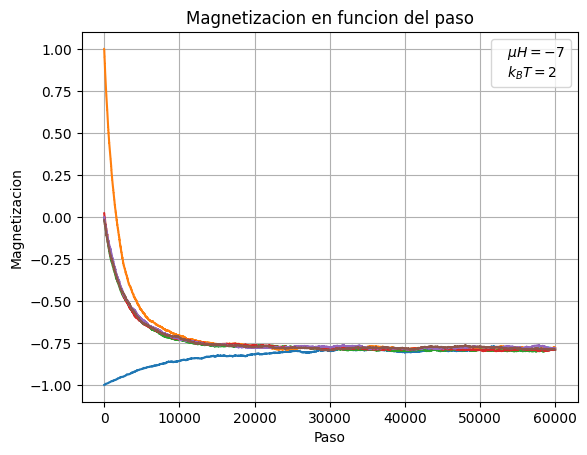

In [ ]:
for i in magnetizaciones:
    plt.plot(i)


plt.legend([r'$\mu H = -7$' + '\n' + r'$k_B T = 2$'], handlelength=0)
plt.grid()
plt.xlabel("Paso")
plt.ylabel("Magnetizacion")
plt.title("Magnetizacion en funcion del paso")
plt.savefig("Ergo.png")
plt.show()

In [ ]:
cant_simulaciones = 10 #10

resultados = np.zeros((cant_simulaciones,Total_H))
Soluciones = []
temperaturas = [0.5,1.5,2.5]

for kb_T in temperaturas:
    print(f"Temperatura = {kb_T}")
    for simulacion in range(cant_simulaciones):
        H_maximo = 10
        campo_aplicado = np.linspace(-H_maximo,H_maximo,Total_H)
        magnetizacion = np.zeros(Total_H)


        cosenos = -np.ones(N) #np.random.uniform(-1, 1, N)
        for j,mu_H in enumerate(campo_aplicado):
            # mu_H = 7
            # kb_T = 1

            acumulado = 0

            if j == 0:
                iteraciones_totales = 60000 # 60000
            else:
                iteraciones_totales = 6000 # 6000

            for iteracion in range(iteraciones_totales):
                i = np.random.randint(N)
                new_coseno = np.random.uniform(-1,1)
                Delta_E = -mu_H*(new_coseno - cosenos[i])
                Prob_cambio = np.exp(-Delta_E/kb_T)

                if Delta_E <= 0 or np.random.random() < Prob_cambio:
                    cosenos[i] = new_coseno

                if iteraciones_totales - iteracion < 1000:
                    acumulado += cosenos.sum()/N

            promedio_cosenos = acumulado/1000

            magnetizacion[j] = promedio_cosenos

        resultados[simulacion] = magnetizacion
        print(f"   Simulacion {simulacion + 1} compeltada")

    # Calcular el promedio de las simulaciones
    promedio_simulaciones = np.zeros(Total_H)
    errores_simulaciones = np.zeros(Total_H)
    for i in range(Total_H):
        promedio_simulaciones[i] = resultados[:,i].mean()
        errores_simulaciones[i] = resultados[:,i].std()

    Soluciones.append([campo_aplicado,promedio_simulaciones,errores_simulaciones])
    print()


Temperatura = 0.5
   Simulacion 1 compeltada
   Simulacion 2 compeltada
   Simulacion 3 compeltada
   Simulacion 4 compeltada
   Simulacion 5 compeltada
   Simulacion 6 compeltada
   Simulacion 7 compeltada
   Simulacion 8 compeltada
   Simulacion 9 compeltada
   Simulacion 10 compeltada

Temperatura = 1.5
   Simulacion 1 compeltada
   Simulacion 2 compeltada
   Simulacion 3 compeltada
   Simulacion 4 compeltada
   Simulacion 5 compeltada
   Simulacion 6 compeltada
   Simulacion 7 compeltada
   Simulacion 8 compeltada
   Simulacion 9 compeltada
   Simulacion 10 compeltada

Temperatura = 2.5
   Simulacion 1 compeltada
   Simulacion 2 compeltada
   Simulacion 3 compeltada
   Simulacion 4 compeltada
   Simulacion 5 compeltada
   Simulacion 6 compeltada
   Simulacion 7 compeltada
   Simulacion 8 compeltada
   Simulacion 9 compeltada
   Simulacion 10 compeltada



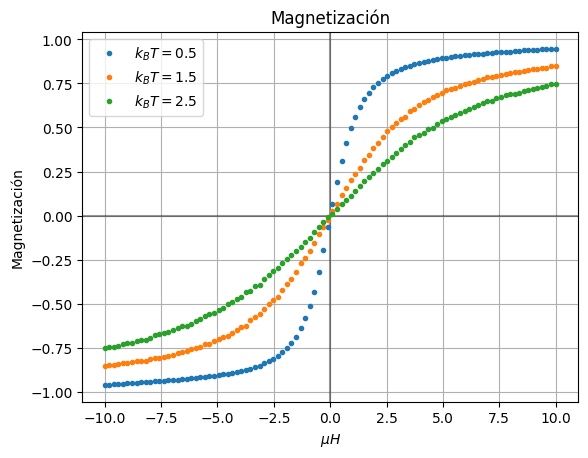

In [ ]:
plt.axvline(0,color='black', linestyle='-', linewidth=1.5, alpha=0.4 )
plt.axhline(0,color='black', linestyle='-', linewidth=1.5, alpha=0.4 )
#plt.plot(campo_aplicado, Langevin(campo_aplicado),'--',label="Curva Teorica")
for j,solucion in enumerate(Soluciones):
    plt.plot(solucion[0], solucion[1],'.',label=r"$k_B T = {}$".format(temperaturas[j]))
    # plt.errorbar(solucion[0], solucion[1],yerr=solucion[2],fmt='o',capsize=0,markersize=2 )
    # Las barras de error son muy pequeñas comparadas con el tamaño del simbolo

plt.legend()
plt.grid()
plt.xlabel(r"$\mu H$")
plt.ylabel("Magnetización")
plt.title("Magnetización")
plt.savefig("MagSimple.png")
plt.show()

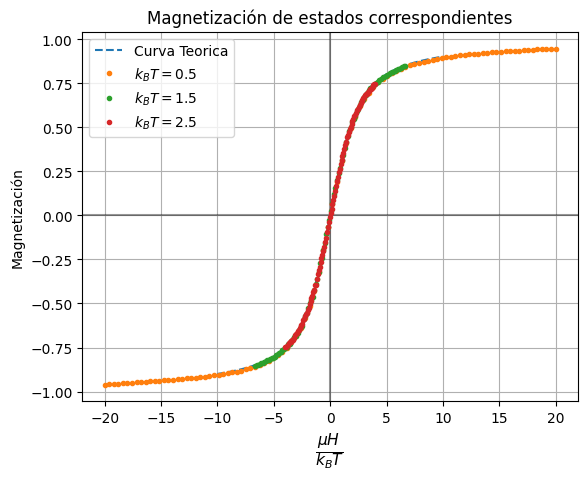

In [ ]:
plt.axvline(0,color='black', linestyle='-', linewidth=1.5, alpha=0.4 )
plt.axhline(0,color='black', linestyle='-', linewidth=1.5, alpha=0.4 )
plt.plot(campo_aplicado, Langevin(campo_aplicado),'--',label="Curva Teorica")
for j,solucion in enumerate(Soluciones):
    plt.plot(solucion[0]/temperaturas[j], solucion[1],'.',label=r"$k_B T = {}$".format(temperaturas[j]))
plt.legend()
plt.grid()
plt.xlim()
plt.ylabel("Magnetización")
plt.title("Magnetización de estados correspondientes")
plt.xlabel(r"$\frac{\mu H}{k_B T}$" ,fontsize=16)
plt.savefig("MagCorrespondientes.png", bbox_inches='tight')
plt.show()

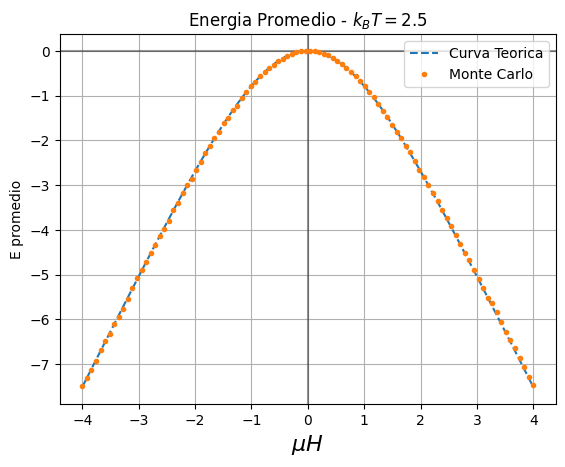

In [ ]:
eta = campo_aplicado/kb_T

plt.axvline(0,color='black', linestyle='-', linewidth=1.5, alpha=0.4 )
plt.axhline(0,color='black', linestyle='-', linewidth=1.5, alpha=0.4 )

plt.plot(eta,-campo_aplicado*Langevin(eta),'--',label="Curva Teorica")
plt.plot(eta, -campo_aplicado*promedio_simulaciones,'.',label="Monte Carlo")

plt.legend()
plt.grid()
plt.xlabel(r"$\mu H$", fontsize=16)

plt.ylabel("E promedio")

plt.title("Energia Promedio - " + r"$k_B T = {}$".format(kb_T))
plt.savefig("Energia.png", bbox_inches='tight')
plt.show()

### **Partículas en un pozo de potencial**



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm

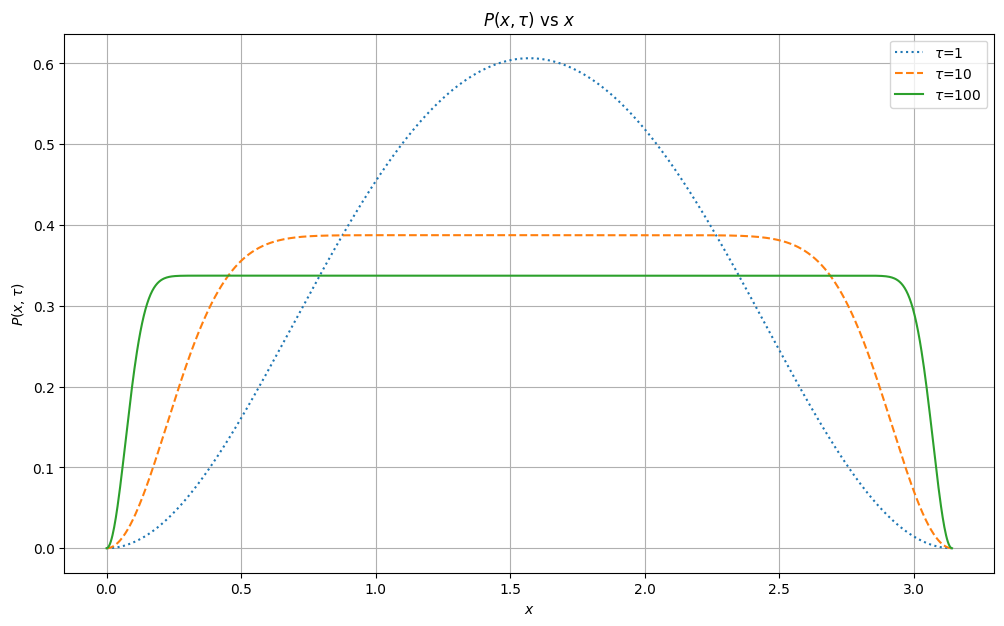

In [ ]:
@np.vectorize
def P_th(x, t, N):
    n = np.arange(1, N+1)
    numerador = np.sum(np.exp(-n**2 / t) * np.sin(n * x)**2)
    denominador = np.sum(np.exp(-n**2 / t))
    return (2/np.pi) * numerador / denominador


x = np.linspace(0, np.pi, 1000)

Pth1 = P_th(x, 1, 25)
Pth10 = P_th(x, 10, 25)
Pth100 = P_th(x, 100, 50)

plt.figure(figsize=(12, 7))
plt.title(r"$P(x,\tau)$ vs $x$")
plt.plot(x,Pth1,linestyle=':',label=r"$\tau$=1")
plt.plot(x,Pth10,linestyle='--',label=r"$\tau$=10")
plt.plot(x,Pth100,label=r"$\tau$=100")
plt.xlabel('$x$')
plt.ylabel(r'$P(x,\tau)$')
plt.grid()
plt.legend()
plt.show()


La figura muestra la densidad de probabilidad termalizada $P(x,\tau)$ para distintos
valores de la temperatura adimensional $\tau$. En el régimen de baja temperatura
($\tau=1$) la distribución está dominada por el estado fundamental y reproduce
esencialmente el perfil $\sin^2 x$, con un máximo en el centro del pozo y probabilidad
nula en las paredes. Al aumentar la temperatura ($\tau=10$), contribuyen muchos
autoestados y la distribución se aplana progresivamente en el interior, aunque
permanece una caída abrupta cerca de los bordes. En el régimen de alta temperatura
($\tau=100$), $P(x,\tau)$ es prácticamente constante en casi todo el pozo y se aproxima
a una distribución uniforme, persistiendo únicamente una región muy delgada próxima
a las paredes donde la probabilidad se anula. Este comportamiento ilustra la
competencia entre la tendencia térmica a uniformizar la distribución y las
condiciones de frontera cuánticas del pozo infinito, responsables del denominado
``boundary layer'', efecto que no tendría lugar en un pozo de potencial finito.


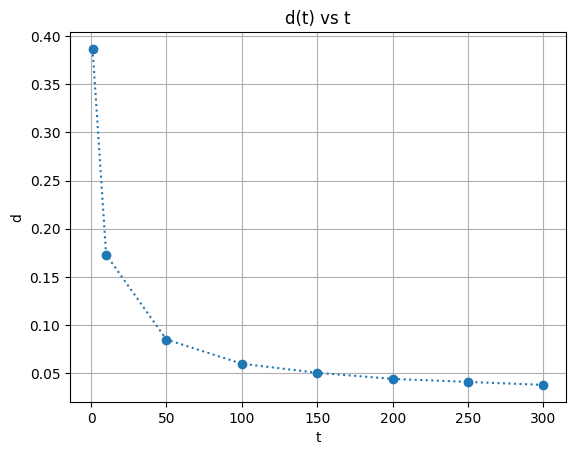

In [ ]:
def d_of_t(t, xgrid, level=0.1):
    P = P_th(xgrid, t,50)
    idx = np.where(P >= level)[0][0]
    return xgrid[idx]

t_vals = np.array([1,10,50,100,150,200,250,300])

d_vals = np.array([d_of_t(t, x) for t in t_vals])

plt.title("d(t) vs t")
plt.plot(t_vals, d_vals, 'o:')
plt.xlabel("t")
plt.ylabel("d")
plt.grid()
plt.show()



### Densidad de probabilidad de dos partículas en una caja sin Espín

In [ ]:
def probability_density_boson(x1, x2, n1, n2):
    """Densidad de probabilidad para bosones"""
    term1 = np.sin(n1 * x1) * np.sin(n2 * x2)
    term2 = np.sin(n1 * x2) * np.sin(n2 * x1)
    P = (2 / np.pi**2) * (term1 + term2)**2
    return P

def probability_density_fermion(x1, x2, n1, n2):
    """Densidad de probabilidad para fermiones"""
    term1 = np.sin(n1 * x1) * np.sin(n2 * x2)
    term2 = np.sin(n1 * x2) * np.sin(n2 * x1)
    P = (2 / np.pi**2) * (term1 - term2)**2
    return P

In [ ]:
def graficar(n1,n2,opcion):
  x = np.linspace(0, np.pi, 1000)
  x1, x2 = np.meshgrid(x, x)

  # Crear figura
  fig = plt.figure(figsize=(7, 6))
  ax = fig.add_subplot(111, projection='3d')

  # Graficar superficie con estilo similar a la imagen

  if opcion == 1:
    surf = ax.plot_surface(x1, x2, probability_density_boson(x1, x2, n1, n2),
                        cmap=cm.YlOrRd,           # Colormap amarillo-naranja-rojo
                        linewidth=0.3,             # Líneas de malla delgadas
                        edgecolor='black',         # Líneas negras
                        alpha=0.95,                # Casi opaco
                        antialiased=True,          # Suavizado
                        shade=True)                # Sombreado
    ax.set_title(f'Densidad de Probabilidad Bosones: $n_1$={n1}, $n_2$={n2}')

  elif opcion == 2:
    surf = ax.plot_surface(x1, x2, probability_density_fermion(x1, x2, n1, n2),
                        cmap=cm.YlOrRd,           # Colormap amarillo-naranja-rojo
                        linewidth=0.3,             # Líneas de malla delgadas
                        edgecolor='black',         # Líneas negras
                        alpha=0.95,                # Casi opaco
                        antialiased=True,          # Suavizado
                        shade=True)                # Sombreado

    ax.set_title(f'Densidad de Probabilidad Fermiones: $n_1$={n1}, $n_2$={n2}')

  # Configurar etiquetas
  ax.set_xlabel(r'$x_1$', fontsize=11, labelpad=8)
  ax.set_ylabel(r'$x_2$', fontsize=11, labelpad=8)
  ax.set_zlabel(r'$P$', fontsize=11, labelpad=8)

  # Configurar límites de los ejes
  ax.set_xlim(0, np.pi)
  ax.set_ylim(0, np.pi)
  ax.set_zlim(0, 1.0)

  # Configurar ticks del eje Z
  ax.set_zticks([0.0, 0.5, 1.0])

  # Ajustar ángulo de vista (similar a la imagen)
  ax.view_init(elev=20, azim=225)  # elev: elevación, azim: azimut

  # Configurar el fondo y la caja
  ax.xaxis.pane.fill = False
  ax.yaxis.pane.fill = False
  ax.zaxis.pane.fill = False
  ax.xaxis.pane.set_edgecolor('gray')
  ax.yaxis.pane.set_edgecolor('gray')
  ax.zaxis.pane.set_edgecolor('gray')
  ax.xaxis.pane.set_alpha(0.3)
  ax.yaxis.pane.set_alpha(0.3)
  ax.zaxis.pane.set_alpha(0.3)

  # Ajustar espaciado
  plt.tight_layout()

  plt.show()


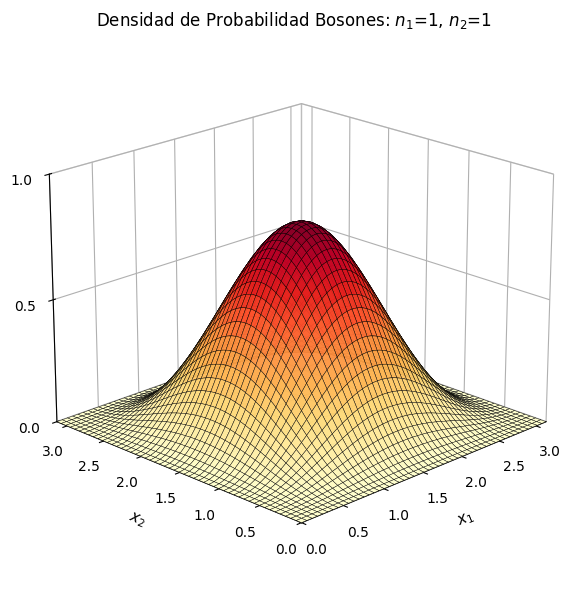

In [ ]:
graficar(1,1,1)

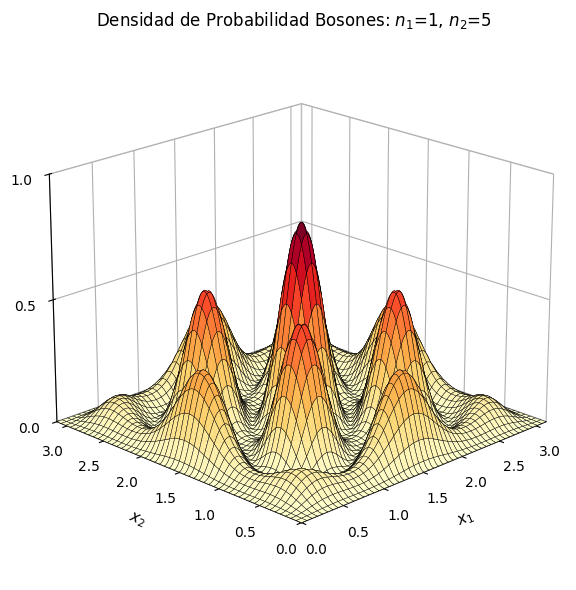

In [ ]:
graficar(1,5,1)

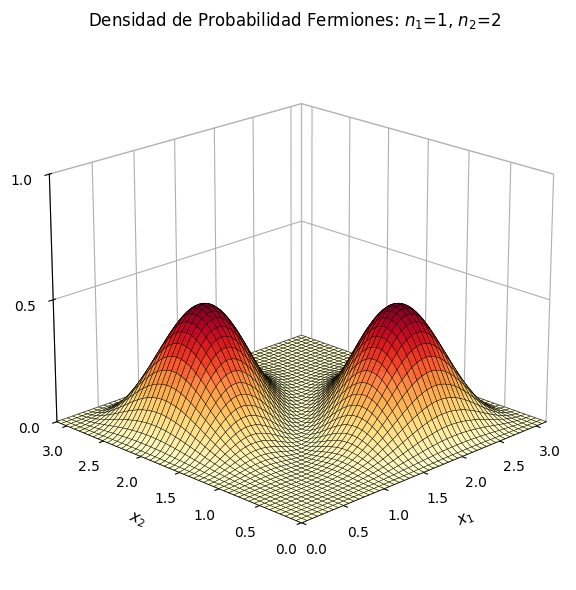

In [ ]:
graficar(1,2,2)

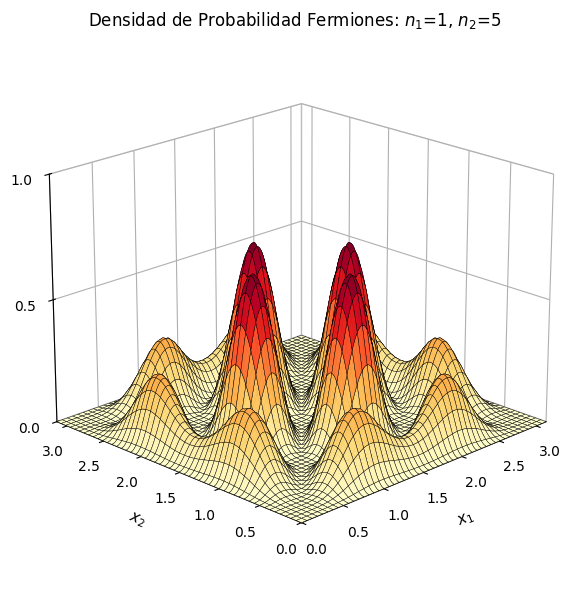

In [ ]:
graficar(1,5,2)

###Densidad de probabilidad de dos partículas sin espín con el aumento de la temperatura

In [ ]:
def E(n1, n2):
    return n1**2 + n2**2


def Pth_fermion(x1, x2, t, nmax=25):
    """
    Probabilidad térmica para fermiones

    Corrección: El segundo loop va desde n2 = n1+1 hasta nmax
    (no hasta nmax+1)
    """
    num = 0.0
    Z = 0.0

    for n1 in range(1, nmax + 1):           # n1 = 1 hasta nmax
        for n2 in range(n1 + 1, nmax + 1):  # n2 = n1+1 hasta nmax
            En = E(n1, n2)
            w = np.exp(-En / t)
            num += probability_density_fermion(x1, x2, n1, n2) * w
            Z   += w

    return num / Z


def Pth_boson(x1, x2, t, nmax=25):
    """
    Probabilidad térmica para bosones

    Corrección: El segundo loop va desde n2 = n1 hasta nmax
    (no hay cambio aquí, pero el primer loop debe llegar hasta nmax)
    """
    num = 0.0
    Z = 0.0

    for n1 in range(1, nmax + 1):        # n1 = 1 hasta nmax
        for n2 in range(n1, nmax + 1):   # n2 = n1 hasta nmax
            En = E(n1, n2)
            w = np.exp(-En / t)
            num += probability_density_boson(x1, x2, n1, n2) * w
            Z   += w

    return num / Z


In [ ]:
def graficar_thermal(n1,n2,t,opcion):
  x = np.linspace(0, np.pi, 1000)
  x1, x2 = np.meshgrid(x, x)

  # Crear figura
  fig = plt.figure(figsize=(7, 6))
  ax = fig.add_subplot(111, projection='3d')

  # Graficar superficie con estilo similar a la imagen

  if opcion == 1:
    surf = ax.plot_surface(x1, x2, Pth_boson(x1, x2, t, nmax=25),
                        cmap=cm.YlOrRd,           # Colormap amarillo-naranja-rojo
                        linewidth=0.3,             # Líneas de malla delgadas
                        edgecolor='black',         # Líneas negras
                        alpha=0.95,                # Casi opaco
                        antialiased=True,          # Suavizado
                        shade=True)                # Sombreado
    ax.set_title(rf'Densidad de Probabilidad Termalizada Bosones $\tau$={t}')

  elif opcion == 2:
    surf = ax.plot_surface(x1, x2,  Pth_fermion(x1, x2, t, nmax=25),
                        cmap=cm.YlOrRd,           # Colormap amarillo-naranja-rojo
                        linewidth=0.3,             # Líneas de malla delgadas
                        edgecolor='black',         # Líneas negras
                        alpha=0.95,                # Casi opaco
                        antialiased=True,          # Suavizado
                        shade=True)                # Sombreado

    ax.set_title(rf'Densidad de Probabilidad Termalizada Fermiones $\tau$={t}')

  # Configurar etiquetas
  ax.set_xlabel(r'$x_1$', fontsize=11, labelpad=8)
  ax.set_ylabel(r'$x_2$', fontsize=11, labelpad=8)
  ax.set_zlabel(r'$P$', fontsize=11, labelpad=8)

  # Configurar límites de los ejes
  ax.set_xlim(0, np.pi)
  ax.set_ylim(0, np.pi)
  ax.set_zlim(0, 1.0)

  # Configurar ticks del eje Z
  ax.set_zticks([0.0, 0.5, 1.0])

  # Ajustar ángulo de vista (similar a la imagen)
  ax.view_init(elev=20, azim=225)  # elev: elevación, azim: azimut

  # Configurar el fondo y la caja
  ax.xaxis.pane.fill = False
  ax.yaxis.pane.fill = False
  ax.zaxis.pane.fill = False
  ax.xaxis.pane.set_edgecolor('gray')
  ax.yaxis.pane.set_edgecolor('gray')
  ax.zaxis.pane.set_edgecolor('gray')
  ax.xaxis.pane.set_alpha(0.3)
  ax.yaxis.pane.set_alpha(0.3)
  ax.zaxis.pane.set_alpha(0.3)

  # Ajustar espaciado
  plt.tight_layout()

  plt.show()


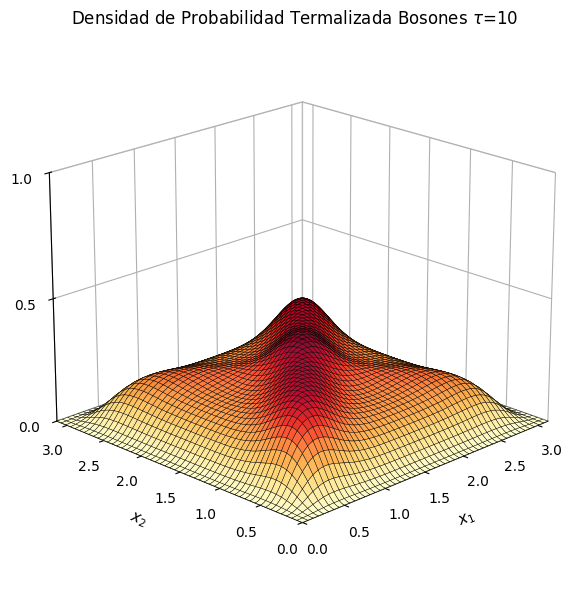

In [ ]:
graficar_thermal(1,1,10,1)

In [ ]:
graficar_thermal(1,2,10,2)

### Densidad de probabilidad de dos fermiones con espín y aumento de la temperatura

In [ ]:
def probability_density_fermion_spin(x1, x2, n1, n2):
    """Densidad de probabilidad para fermiones con spin

    P(x1, x2) = (1/(2π²)) [sin(n1·x1)sin(n2·x2) + sin(n1·x2)sin(n2·x1)]²
              + (3/(2π²)) [sin(n1·x1)sin(n2·x2) - sin(n1·x2)sin(n2·x1)]²
    """
    term1 = np.sin(n1 * x1) * np.sin(n2 * x2)
    term2 = np.sin(n1 * x2) * np.sin(n2 * x1)
    P = (1 / (2 * np.pi**2)) * (term1 + term2)**2 + (3 / (2 * np.pi**2)) * (term1 - term2)**2
    return P

In [ ]:
def graficar_density_spin(n1,n2):
  x = np.linspace(0, np.pi, 1000)
  x1, x2 = np.meshgrid(x, x)

  # Crear figura
  fig = plt.figure(figsize=(7, 6))
  ax = fig.add_subplot(111, projection='3d')

  # Graficar superficie con estilo similar a la imagen


  surf = ax.plot_surface(x1, x2, probability_density_fermion_spin(x1, x2, n1, n2),
                      cmap=cm.YlOrRd,           # Colormap amarillo-naranja-rojo
                      linewidth=0.3,             # Líneas de malla delgadas
                      edgecolor='black',         # Líneas negras
                      alpha=0.95,                # Casi opaco
                      antialiased=True,          # Suavizado
                      shade=True)                # Sombreado


  ax.set_title(f'Densidad de Probabilidad de Fermiones con Espín: $n_1$={n1}, $n_2$={n2}')

  # Configurar etiquetas
  ax.set_xlabel(r'$x_1$', fontsize=11, labelpad=8)
  ax.set_ylabel(r'$x_2$', fontsize=11, labelpad=8)
  ax.set_zlabel(r'$P$', fontsize=11, labelpad=8)

  # Configurar límites de los ejes
  ax.set_xlim(0, np.pi)
  ax.set_ylim(0, np.pi)
  ax.set_zlim(0, 1.0)

  # Configurar ticks del eje Z
  ax.set_zticks([0.0, 0.5, 1.0])

  # Ajustar ángulo de vista (similar a la imagen)
  ax.view_init(elev=20, azim=225)  # elev: elevación, azim: azimut

  # Configurar el fondo y la caja
  ax.xaxis.pane.fill = False
  ax.yaxis.pane.fill = False
  ax.zaxis.pane.fill = False
  ax.xaxis.pane.set_edgecolor('gray')
  ax.yaxis.pane.set_edgecolor('gray')
  ax.zaxis.pane.set_edgecolor('gray')
  ax.xaxis.pane.set_alpha(0.3)
  ax.yaxis.pane.set_alpha(0.3)
  ax.zaxis.pane.set_alpha(0.3)

  # Ajustar espaciado
  plt.tight_layout()

  plt.show()

In [ ]:
graficar_density_spin(1,2)

In [ ]:
graficar_density_spin(1,5)

In [ ]:
def Pth_fermion_spin(x1, x2, t, nmax=25):
    """
    Probabilidad térmica para fermiones

    Corrección: El segundo loop va desde n2 = n1+1 hasta nmax
    (no hasta nmax+1)
    """
    num = 0.0
    Z = 0.0

    for n1 in range(1, nmax + 1):           # n1 = 1 hasta nmax
        for n2 in range(n1 + 1, nmax + 1):  # n2 = n1+1 hasta nmax (CORREGIDO)
            En = E(n1, n2)
            w = np.exp(-En / t)
            num += probability_density_fermion_spin(x1, x2, n1, n2) * w
            Z   += w

    return num / Z

In [ ]:
def graficar_thermal_fermion_spin(n1,n2,t):
  x = np.linspace(0, np.pi, 1000)
  x1, x2 = np.meshgrid(x, x)

  # Crear figura
  fig = plt.figure(figsize=(7, 6))
  ax = fig.add_subplot(111, projection='3d')

  # Graficar superficie con estilo similar a la imagen


  surf = ax.plot_surface(x1, x2, Pth_fermion_spin(x1, x2, t, nmax=25),
                      cmap=cm.YlOrRd,           # Colormap amarillo-naranja-rojo
                      linewidth=0.3,             # Líneas de malla delgadas
                      edgecolor='black',         # Líneas negras
                      alpha=0.95,                # Casi opaco
                      antialiased=True,          # Suavizado
                      shade=True)                # Sombreado
  ax.set_title(rf'Densidad de Probabilidad Termalizada de Fermiones con Espín $\tau$={t}')



  # Configurar etiquetas
  ax.set_xlabel(r'$x_1$', fontsize=11, labelpad=8)
  ax.set_ylabel(r'$x_2$', fontsize=11, labelpad=8)
  ax.set_zlabel(r'$P$', fontsize=11, labelpad=8)

  # Configurar límites de los ejes
  ax.set_xlim(0, np.pi)
  ax.set_ylim(0, np.pi)
  ax.set_zlim(0, 1.0)

  # Configurar ticks del eje Z
  ax.set_zticks([0.0, 0.5, 1.0])

  # Ajustar ángulo de vista (similar a la imagen)
  ax.view_init(elev=20, azim=225)  # elev: elevación, azim: azimut

  # Configurar el fondo y la caja
  ax.xaxis.pane.fill = False
  ax.yaxis.pane.fill = False
  ax.zaxis.pane.fill = False
  ax.xaxis.pane.set_edgecolor('gray')
  ax.yaxis.pane.set_edgecolor('gray')
  ax.zaxis.pane.set_edgecolor('gray')
  ax.xaxis.pane.set_alpha(0.3)
  ax.yaxis.pane.set_alpha(0.3)
  ax.zaxis.pane.set_alpha(0.3)

  # Ajustar espaciado
  plt.tight_layout()

  plt.show()

In [ ]:
graficar_thermal_fermion_spin(1,1,10)

### Densidad de probabilidad deuna partícula en un pozo de potencial finito

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


In [ ]:
a = 1.0      # ancho del pozo
V0 = 200.0   # profundidad


def k(E):
    return np.sqrt(E)

def kappa(E):
    return np.sqrt(V0 - E)

def f_even(E):
    return k(E)*np.tan(k(E)*a/2) - kappa(E)

def f_odd(E):
    return -k(E)/np.tan(k(E)*a/2) - kappa(E)


In [ ]:
def find_levels(f, Emax=200, N=20000):
    E = np.linspace(1e-6, Emax, N)
    vals = f(E)
    roots = []

    for i in range(len(E)-1):
        if vals[i]*vals[i+1] < 0:
            root = brentq(f, E[i], E[i+1])
            roots.append(root)
    return roots


In [ ]:
E_even = find_levels(f_even, V0)
E_odd  = find_levels(f_odd,  V0)

E_finite = sorted(E_even + E_odd)
print("Niveles pozo finito:")
for i,E in enumerate(E_finite):
    print(i+1, E)


In [ ]:
n = np.arange(1, len(E_finite)+1)
E_inf = (n*np.pi/a)**2
E_inf

In [ ]:
plt.figure()
plt.plot(n, E_finite, 'o', label="Pozo finito")
plt.plot(n, E_inf[:len(E_finite)], 's--', label="Pozo infinito")
plt.xlabel("n")
plt.ylabel("E")
plt.legend()
plt.title("Comparación de niveles de energía")
plt.grid()
plt.show()


In [ ]:
def psi_even(x, E):
    k_val = k(E)
    kap = kappa(E)
    A = np.cos(k_val*a/2)

    psi = np.zeros_like(x)
    for i,xi in enumerate(x):
        if abs(xi) <= a/2:
            psi[i] = np.cos(k_val*xi)
        elif xi > a/2:
            psi[i] = A*np.exp(-kap*(xi-a/2))
        else:
            psi[i] = A*np.exp(kap*(xi+a/2))
    return psi


In [ ]:
x = np.linspace(-1.5, 1.5, 2000)

E0 = E_even[0]
psi_finite = psi_even(x, E0)

psi_inf = np.zeros_like(x)
inside = np.abs(x) <= a/2
psi_inf[inside] = np.cos(np.pi*x[inside]/a)

plt.figure(figsize=(7,4))
plt.plot(x, psi_finite/np.max(np.abs(psi_finite)), label="Pozo finito")
plt.plot(x, psi_inf/np.max(np.abs(psi_inf)), '--', label="Pozo infinito")
plt.axvline(a/2, color='k', linestyle=':')
plt.axvline(-a/2, color='k', linestyle=':')
plt.xlabel("x")
plt.ylabel("ψ(x)")
plt.title("Estado fundamental: pozo finito vs infinito")
plt.legend()
plt.grid()
plt.show()


ESTADOS LIGADOS DEL POZO FINITO
Parámetros: a=1.5707963267948966, V0=5

Total de estados: 4

  n=0: E =   0.3451, Paridad: even
  n=1: E =   1.3620, Paridad: odd 
  n=2: E =   2.9748, Paridad: even
  n=3: E =   4.8447, Paridad: odd 

VERIFICACIÓN DE NORMALIZACIÓN
Estado n=0 (even): ∫P(x)dx = 1.000000
Estado n=1 (odd ): ∫P(x)dx = 1.000000
Estado n=2 (even): ∫P(x)dx = 1.000000
Estado n=3 (odd ): ∫P(x)dx = 1.000000


/tmp/ipython-input-2778857014.py:108: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.sqrt(np.trapz(psi_norm**2, x_norm))
/tmp/ipython-input-2778857014.py:181: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  integral = np.trapz(P, x_test)
/tmp/ipython-input-2778857014.py:152: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  norm = np.sqrt(np.trapz(psi_norm**2, x_norm))


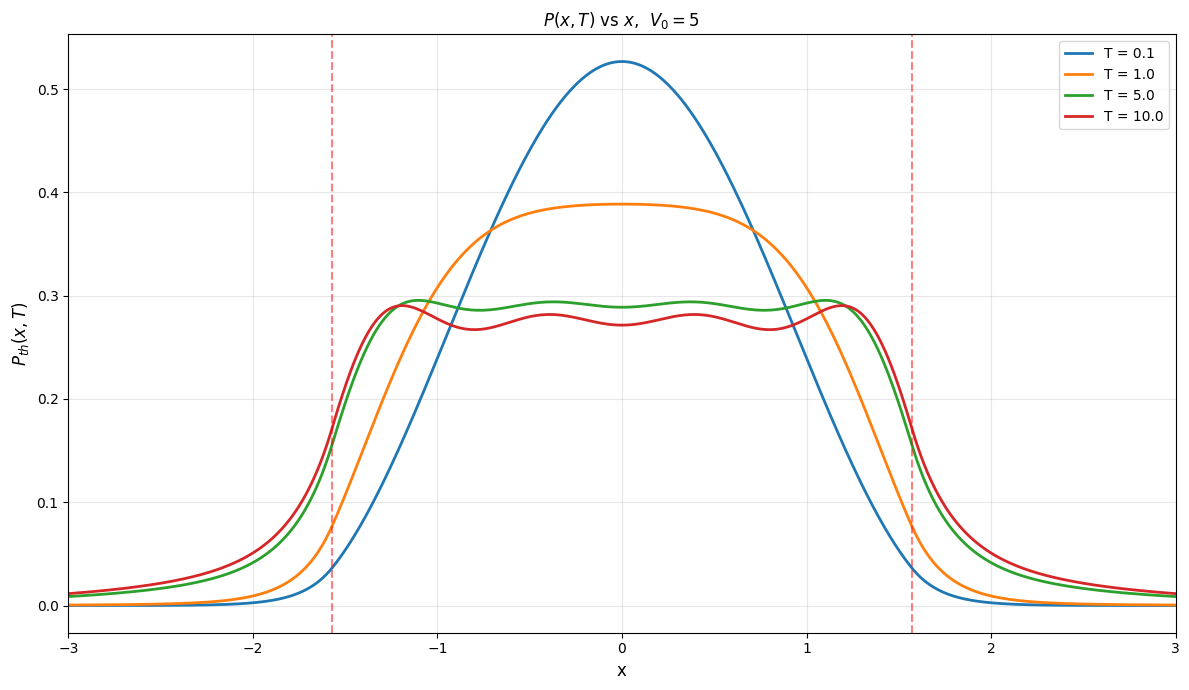

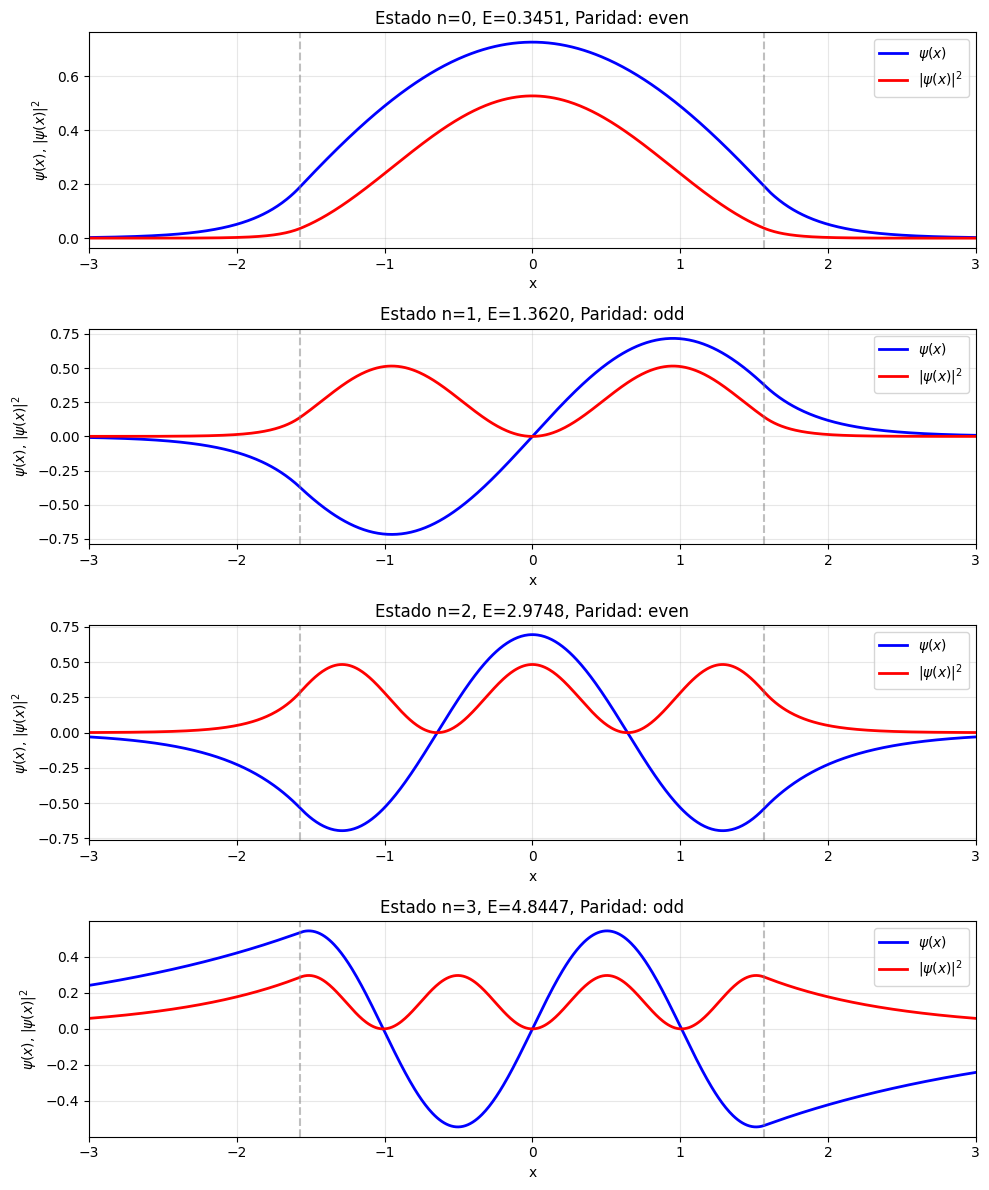

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ============================================
# PARÁMETROS DEL POZO FINITO
# ============================================
a = np.pi/2      # la anchura del pozo es 2a (pozo de -a a a)
V0 = 5     # altura del pozo
k_B = 1.0    # constante de Boltzmann

# ============================================
# FUNCIONES TRASCENDENTALES
# ============================================
def f(E):  # par
    if E <= 0 or E >= V0:
        return 1e10
    return np.sqrt(2*(V0-E))*np.cos(np.sqrt(2*E)*a) - np.sqrt(2*E)*np.sin(np.sqrt(2*E)*a)

def g(E):  # impar
    if E <= 0 or E >= V0:
        return 1e10
    return np.sqrt(2*E)*np.cos(np.sqrt(2*E)*a) + np.sqrt(2*(V0-E))*np.sin(np.sqrt(2*E)*a)

# ============================================
# BÚSQUEDA DE RAÍCES (ENERGÍAS)
# ============================================
def raices(func, x):
    y = np.array([func(xi) for xi in x])
    roots = []
    for i in range(len(x)-1):
        if y[i]*y[i+1] < 0:
            try:
                roots.append(brentq(func, x[i], x[i+1]))
            except:
                pass
    return np.array(roots)

xx = np.linspace(1e-4, V0-1e-4, 4000)
par = raices(f, xx)
impar = raices(g, xx)

# Combinar y ordenar todas las energías
energies = np.sort(np.concatenate([par, impar]))
parities = []

for E in energies:
    # Determinar si es par o impar
    if any(np.abs(E - par) < 1e-6):
        parities.append('even')
    else:
        parities.append('odd')

print("="*60)
print("ESTADOS LIGADOS DEL POZO FINITO")
print("="*60)
print(f"Parámetros: a={a}, V0={V0}")
print(f"\nTotal de estados: {len(energies)}\n")

for i, (E, parity) in enumerate(zip(energies, parities)):
    print(f"  n={i}: E = {E:8.4f}, Paridad: {parity:4s}")

# ============================================
# FUNCIONES DE ONDA NORMALIZADAS
# ============================================

def wavefunction_even(x, E):
    """Función de onda para estado par normalizada"""
    q = np.sqrt(2*E)
    k = np.sqrt(2*(V0-E))

    x = np.asarray(x)
    psi = np.zeros_like(x, dtype=float)

    # Coeficiente B (dentro del pozo)
    B = 1.0  # Lo normalizaremos al final

    # Coeficiente A (fuera del pozo) por continuidad
    A = B * np.cos(q*a) / np.exp(-k*a)

    # Región central |x| <= a
    mask1 = np.abs(x) <= a
    psi[mask1] = B * np.cos(q*x[mask1])

    # Región derecha x > a
    mask2 = x > a
    psi[mask2] = A * np.exp(-k*x[mask2])

    # Región izquierda x < -a (simétrica)
    mask3 = x < -a
    psi[mask3] = A * np.exp(k*x[mask3])

    # Calcular la integral de normalización numéricamente
    dx = 0.001
    x_norm = np.arange(-10*a, 10*a, dx)
    psi_norm = wavefunction_even(x_norm, E) if np.all(psi == 0) else psi

    # Recalcular sin normalizar para la integral
    psi_norm = np.zeros_like(x_norm)
    mask1 = np.abs(x_norm) <= a
    mask2 = x_norm > a
    mask3 = x_norm < -a

    psi_norm[mask1] = B * np.cos(q*x_norm[mask1])
    psi_norm[mask2] = A * np.exp(-k*x_norm[mask2])
    psi_norm[mask3] = A * np.exp(k*x_norm[mask3])

    norm = np.sqrt(np.trapz(psi_norm**2, x_norm))

    return psi / norm


def wavefunction_odd(x, E):
    """Función de onda para estado impar normalizada"""
    q = np.sqrt(2*E)
    k = np.sqrt(2*(V0-E))

    x = np.asarray(x)
    psi = np.zeros_like(x, dtype=float)

    # Coeficiente B (dentro del pozo)
    B = 1.0  # Lo normalizaremos al final

    # Coeficiente A (fuera del pozo) por continuidad
    A = B * np.sin(q*a) / np.exp(-k*a)

    # Región central |x| <= a
    mask1 = np.abs(x) <= a
    psi[mask1] = B * np.sin(q*x[mask1])

    # Región derecha x > a
    mask2 = x > a
    psi[mask2] = A * np.exp(-k*x[mask2])

    # Región izquierda x < -a (antisimétrica)
    mask3 = x < -a
    psi[mask3] = -A * np.exp(k*x[mask3])

    # Calcular la integral de normalización numéricamente
    dx = 0.001
    x_norm = np.arange(-10*a, 10*a, dx)

    psi_norm = np.zeros_like(x_norm)
    mask1 = np.abs(x_norm) <= a
    mask2 = x_norm > a
    mask3 = x_norm < -a

    psi_norm[mask1] = B * np.sin(q*x_norm[mask1])
    psi_norm[mask2] = A * np.exp(-k*x_norm[mask2])
    psi_norm[mask3] = -A * np.exp(k*x_norm[mask3])

    norm = np.sqrt(np.trapz(psi_norm**2, x_norm))

    return psi / norm


def get_wavefunction(x, E, parity):
    """Devuelve la función de onda según la paridad"""
    if parity == 'even':
        return wavefunction_even(x, E)
    else:
        return wavefunction_odd(x, E)


def probability_density(x, E, parity):
    """Densidad de probabilidad P(x) = |ψ(x)|²"""
    psi = get_wavefunction(x, E, parity)
    return psi**2


# ============================================
# VERIFICACIÓN DE NORMALIZACIÓN
# ============================================
print("\n" + "="*60)
print("VERIFICACIÓN DE NORMALIZACIÓN")
print("="*60)

x_test = np.linspace(-10*a, 10*a, 5000)
for i, (E, parity) in enumerate(zip(energies, parities)):
    P = probability_density(x_test, E, parity)
    integral = np.trapz(P, x_test)
    print(f"Estado n={i} ({parity:4s}): ∫P(x)dx = {integral:.6f}")

# ============================================
# PROBABILIDAD TÉRMICA
# ============================================

def thermal_probability(x, T, energies, parities):
    """
    Calcula la probabilidad térmica:
    Pth(X, T) = Σ_n P_n(X) exp(-E_n/k_B T) / Z
    """
    x = np.asarray(x)
    Pth = np.zeros_like(x, dtype=float)
    Z = 0.0  # Función de partición

    for E, parity in zip(energies, parities):
        w = np.exp(-E / (k_B * T))
        Z += w

        P_n = probability_density(x, E, parity)
        Pth += P_n * w

    return Pth / Z


# ============================================
# GRÁFICAS
# ============================================

x_range = np.linspace(-4, 4, 1000)

# Temperaturas a graficar
temperatures = [0.1, 1.0, 5.0, 10.0]

# ============================================
# FIGURA 1: Probabilidad térmica para diferentes T
# ============================================

fig1, ax1 = plt.subplots(figsize=(12, 7))
plt.title(rf"$P(x,T)$ vs $x$,  $V_0 = {V0}$")

for i, T in enumerate(temperatures):
    Pth = thermal_probability(x_range, T, energies, parities)
    plt.plot(x_range, Pth, label=f'T = {T}', linewidth=2)

plt.xlabel('x', fontsize=12)
plt.ylabel(r'$P_{th}(x,T)$', fontsize=12)
plt.grid(alpha=0.3)
plt.legend(fontsize=10)
plt.axvline(-a, color='red', linestyle='--', alpha=0.5, label='Paredes del pozo')
plt.axvline(a, color='red', linestyle='--', alpha=0.5)
plt.xlim(-3, 3)
plt.tight_layout()
plt.show()

# ============================================
# FIGURA 2: Funciones de onda individuales
# ============================================

fig2, axes = plt.subplots(len(energies), 1, figsize=(10, 3*len(energies)))
if len(energies) == 1:
    axes = [axes]

for i, (E, parity, ax) in enumerate(zip(energies, parities, axes)):
    psi = get_wavefunction(x_range, E, parity)
    P = probability_density(x_range, E, parity)

    ax.plot(x_range, psi, 'b-', label=r'$\psi(x)$', linewidth=2)
    ax.plot(x_range, P, 'r-', label=r'$|\psi(x)|^2$', linewidth=2)
    ax.axvline(-a, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(a, color='gray', linestyle='--', alpha=0.5)
    ax.set_title(f'Estado n={i}, E={E:.4f}, Paridad: {parity}')
    ax.set_xlabel('x')
    ax.set_ylabel(r'$\psi(x)$, $|\psi(x)|^2$')
    ax.legend()
    ax.grid(alpha=0.3)
    ax.set_xlim(-3, 3)

plt.tight_layout()
plt.show()

In [ ]:
a

1.5707963267948966

### Densidad de probabilidad de dos fermiones con espín y aumento de la temperatura en un pozo finito

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from scipy.optimize import brentq

# Funciones para encontrar los niveles de energía
def f_even(E, V0, a):  # Para estados pares
    if E <= 0 or E >= V0:
        return 1e10
    return np.sqrt(2*(V0-E))*np.cos(np.sqrt(2*E)*a) - np.sqrt(2*E)*np.sin(np.sqrt(2*E)*a)

def f_odd(E, V0, a):   # Para estados impares
    if E <= 0 or E >= V0:
        return 1e10
    return np.sqrt(2*E)*np.cos(np.sqrt(2*E)*a) + np.sqrt(2*(V0-E))*np.sin(np.sqrt(2*E)*a)

# Encontrar las raíces (niveles de energía)
def find_roots(func, x_min, x_max, V0, a, n_points=1000):
    x = np.linspace(x_min, x_max, n_points)
    y = np.array([func(xi, V0, a) for xi in x])
    roots = []
    for i in range(len(x)-1):
        if y[i]*y[i+1] < 0:
            try:
                root = brentq(lambda E: func(E, V0, a), x[i], x[i+1])
                roots.append(root)
            except:
                pass
    return np.array(roots)

# Funciones de onda para el pozo finito
def wavefunction_even(x, E, V0, a):
    """Función de onda para estado par en pozo finito"""
    q = np.sqrt(2*E)
    k = np.sqrt(2*(V0-E))

    # Coeficiente para continuidad
    A = np.cos(q*a)

    # Crear la función de onda
    x = np.asarray(x)
    psi = np.zeros_like(x, dtype=float)

    # Región central |x| <= a
    mask1 = np.abs(x) <= a
    psi[mask1] = np.cos(q*x[mask1])

    # Región derecha x > a
    mask2 = x > a
    psi[mask2] = A*np.exp(-k*(x[mask2]-a))

    # Región izquierda x < -a
    mask3 = x < -a
    psi[mask3] = A*np.exp(k*(x[mask3]+a))

    return psi

def wavefunction_odd(x, E, V0, a):
    """Función de onda para estado impar en pozo finito"""
    q = np.sqrt(2*E)
    k = np.sqrt(2*(V0-E))

    # Coeficiente para continuidad
    A = np.sin(q*a)

    # Crear la función de onda
    x = np.asarray(x)
    psi = np.zeros_like(x, dtype=float)

    # Región central |x| <= a
    mask1 = np.abs(x) <= a
    psi[mask1] = np.sin(q*x[mask1])

    # Región derecha x > a
    mask2 = x > a
    psi[mask2] = A*np.exp(-k*(x[mask2]-a))

    # Región izquierda x < -a
    mask3 = x < -a
    psi[mask3] = -A*np.exp(k*(x[mask3]+a))

    return psi

def get_wavefunction(x, E, parity, V0, a):
    """Devuelve la función de onda según la paridad"""
    if parity == 'even':
        return wavefunction_even(x, E, V0, a)
    else:
        return wavefunction_odd(x, E, V0, a)

def get_energy_levels(V0, a):
    """Calcula los niveles de energía y sus paridades para un pozo finito"""
    # Encontrar los niveles de energía
    energies_even = find_roots(f_even, 1e-6, V0-1e-6, V0, a, n_points=5000)
    energies_odd = find_roots(f_odd, 1e-6, V0-1e-6, V0, a, n_points=5000)

    # Combinar y ordenar todos los niveles
    energies = np.sort(np.concatenate([energies_even, energies_odd]))
    parities = []

    for E in energies:
        if any(np.abs(E - energies_even) < 1e-6):
            parities.append('even')
        else:
            parities.append('odd')

    return energies, parities

def graficar_fermiones_spin_nivel(n1_index, n2_index, V0, a=np.pi/2):
    """
    Grafica la densidad de probabilidad para dos fermiones con spin en niveles específicos.

    Parámetros:
    - n1_index, n2_index: Índices (empezando en 0) de los niveles de energía a usar
    - V0: Altura del pozo (por defecto 5.0)
    - a: Mitad del ancho del pozo (por defecto π/2)
    """
    # Obtener los niveles de energía
    energies, parities = get_energy_levels(V0, a)

    # Verificar que los índices son válidos
    if n1_index >= len(energies) or n2_index >= len(energies) or n1_index < 0 or n2_index < 0:
        print(f"Error: Índices fuera de rango. Deben estar entre 0 y {len(energies)-1}")
        return None, None

    # Obtener las energías y paridades correspondientes
    E1 = energies[n1_index]
    E2 = energies[n2_index]
    parity1 = parities[n1_index]
    parity2 = parities[n2_index]


    # Crear malla de puntos
    x = np.linspace(-2.2, 2.2, 150)
    X1, X2 = np.meshgrid(x, x)

    # Obtener las funciones de onda individuales
    psi1_x1 = get_wavefunction(X1, E1, parity1, V0, a)
    psi1_x2 = get_wavefunction(X2, E1, parity1, V0, a)
    psi2_x1 = get_wavefunction(X1, E2, parity2, V0, a)
    psi2_x2 = get_wavefunction(X2, E2, parity2, V0, a)

    # Para fermiones con spin, la densidad de probabilidad es:
    # P(x1,x2) = (1/4)|ψ_sim(x1,x2)|² + (3/4)|ψ_antisim(x1,x2)|²

    # Función espacial simétrica (para singlete de spin)
    psi_sim = (1/np.sqrt(2)) * (psi1_x1 * psi2_x2 + psi1_x2 * psi2_x1)

    # Función espacial antisimétrica (para triplete de spin)
    psi_antisim = (1/np.sqrt(2)) * (psi1_x1 * psi2_x2 - psi1_x2 * psi2_x1)

    # Densidad de probabilidad total
    density = (1/4) * np.abs(psi_sim)**2 + (3/4) * np.abs(psi_antisim)**2

    # Crear figura 3D
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Graficar superficie
    surf = ax.plot_surface(X1, X2, density,
                          cmap='YlOrRd',
                          linewidth=0.3,
                          edgecolor='black',
                          alpha=0.9,
                          antialiased=True)

    # Configurar gráfica
    title = f"Fermiones con spin - Pozo finito " + r"$(V_0={})$".format(V0) + "\n"
    title += r"$n_1={}$ , $n_2={}$".format(n1_index+1,n2_index+1)
    ax.set_title(title)
    ax.set_xlabel('x₁')
    ax.set_ylabel('x₂')
    ax.set_zlabel('P(x₁,x₂)')

    # Establecer límites de los ejes
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_zlim(0, 1.0)

    # Marcar los límites del pozo
    ax.plot([-a, -a], [-a, a], [0, 0], 'k--', alpha=0.5)
    ax.plot([a, a], [-a, a], [0, 0], 'k--', alpha=0.5)
    ax.plot([-a, a], [-a, -a], [0, 0], 'k--', alpha=0.5)
    ax.plot([-a, a], [a, a], [0, 0], 'k--', alpha=0.5)

    # Ajustar vista
    ax.view_init(elev=30, azim=225)

    # Configurar el fondo y la caja
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('gray')
    ax.yaxis.pane.set_edgecolor('gray')
    ax.zaxis.pane.set_edgecolor('gray')
    ax.xaxis.pane.set_alpha(0.3)
    ax.yaxis.pane.set_alpha(0.3)
    ax.zaxis.pane.set_alpha(0.3)

    plt.tight_layout()
    plt.show()

    return fig, ax

def fermion_spin_density_thermal(x1, x2, T, energies, parities, V0, a, max_states=None):
    """
    Calcula la densidad de probabilidad térmica para fermiones con spin.

    Parámetros:
    - x1, x2: Coordenadas espaciales (meshgrid)
    - T: Temperatura
    - energies: Lista de energías de los estados
    - parities: Lista de paridades de los estados
    - V0: Altura del pozo
    - a: Mitad del ancho del pozo
    - max_states: Número máximo de estados a considerar. Si es None, usa todos los estados disponibles.
    """
    # Si max_states es None, usar todos los estados disponibles
    if max_states is None:
        max_states = len(energies)
    else:
        max_states = min(max_states, len(energies))

    # Inicializar la densidad y la función de partición
    density = np.zeros_like(x1, dtype=float)
    Z = 0.0

    # Sumar sobre todos los pares de estados (i < j)
    for i in range(max_states):
        for j in range(i, max_states):  # Incluir i=j para estados con mismo nivel pero spines opuestos
            # Energía total del par
            E_total = energies[i] + energies[j]

            # Factor de Boltzmann
            w = np.exp(-E_total / T)

            # Obtener las funciones de onda individuales
            psi1_x1 = get_wavefunction(x1, energies[i], parities[i], V0, a)
            psi1_x2 = get_wavefunction(x2, energies[i], parities[i], V0, a)
            psi2_x1 = get_wavefunction(x1, energies[j], parities[j], V0, a)
            psi2_x2 = get_wavefunction(x2, energies[j], parities[j], V0, a)

            # Para fermiones con spin, la densidad de probabilidad es:
            # P(x1,x2) = (1/4)|ψ_sim(x1,x2)|² + (3/4)|ψ_antisim(x1,x2)|²

            # Función espacial simétrica (para singlete de spin)
            psi_sim = (1/np.sqrt(2)) * (psi1_x1 * psi2_x2 + psi1_x2 * psi2_x1)

            # Función espacial antisimétrica (para triplete de spin)
            psi_antisim = (1/np.sqrt(2)) * (psi1_x1 * psi2_x2 - psi1_x2 * psi2_x1)

            # Densidad de probabilidad para este par
            P_ij = (1/4) * np.abs(psi_sim)**2 + (3/4) * np.abs(psi_antisim)**2

            # Acumular la contribución ponderada
            density += P_ij * w
            Z += w

    # Normalizar por la función de partición
    if Z > 0:
        density = density / Z

    return density

def graficar_fermiones_spin_termalizado(T, V0=5.0, a=np.pi/2, max_states=None):
    """
    Grafica la densidad de probabilidad térmica para fermiones con spin.

    Parámetros:
    - T: Temperatura
    - V0: Altura del pozo (por defecto 5.0)
    - a: Mitad del ancho del pozo (por defecto π/2)
    - max_states: Número máximo de estados a considerar. Si es None, usa todos los estados disponibles.
    """
    # Obtener los niveles de energía
    energies, parities = get_energy_levels(V0, a)

    # Si max_states es None, usar todos los estados disponibles
    if max_states is None:
        max_states = len(energies)
    else:
        max_states = min(max_states, len(energies))

    # Imprimir información sobre los estados que se están considerando
    print(f"Considerando {max_states} de {len(energies)} estados disponibles para T={T}")

    # Crear malla de puntos
    x = np.linspace(-2.2, 2.2, 150)
    X1, X2 = np.meshgrid(x, x)

    # Calcular la densidad térmica
    density = fermion_spin_density_thermal(X1, X2, T, energies, parities, V0, a, max_states)

    # Crear figura 3D
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Graficar superficie
    surf = ax.plot_surface(X1, X2, density,
                          cmap='YlOrRd',
                          linewidth=0.3,
                          edgecolor='black',
                          alpha=0.9,
                          antialiased=True)

    # Configurar gráfica
    title = f"Fermiones con spin - Pozo finito " + r"$(V_0={})$".format(V0) + "\n"
    title += f"Temperatura T={T} ({max_states} estados)"
    ax.set_title(title)
    ax.set_xlabel('x₁')
    ax.set_ylabel('x₂')
    ax.set_zlabel('P(x₁,x₂)')

    # Establecer límites de los ejes
    ax.set_xlim(-2.2, 2.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_zlim(0, 1.0)

    # Marcar los límites del pozo
    ax.plot([-a, -a], [-a, a], [0, 0], 'k--', alpha=0.5)
    ax.plot([a, a], [-a, a], [0, 0], 'k--', alpha=0.5)
    ax.plot([-a, a], [-a, -a], [0, 0], 'k--', alpha=0.5)
    ax.plot([-a, a], [a, a], [0, 0], 'k--', alpha=0.5)

    # Ajustar vista
    ax.view_init(elev=30, azim=225)

    # Configurar el fondo y la caja
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
    ax.xaxis.pane.set_edgecolor('gray')
    ax.yaxis.pane.set_edgecolor('gray')
    ax.zaxis.pane.set_edgecolor('gray')
    ax.xaxis.pane.set_alpha(0.3)
    ax.yaxis.pane.set_alpha(0.3)
    ax.zaxis.pane.set_alpha(0.3)

    plt.tight_layout()
    plt.show()

    return fig, ax

def comparar_temperaturas_fermiones_spin(temperatures, V0=5.0, a=np.pi/2, max_states=None):
    """
    Compara la densidad de probabilidad para fermiones con spin a diferentes temperaturas.

    Parámetros:
    - temperatures: Lista de temperaturas a comparar
    - V0: Altura del pozo (por defecto 5.0)
    - a: Mitad del ancho del pozo (por defecto π/2)
    - max_states: Número máximo de estados a considerar. Si es None, usa todos los estados disponibles.
    """
    # Obtener los niveles de energía
    energies, parities = get_energy_levels(V0, a)

    # Si max_states es None, usar todos los estados disponibles
    if max_states is None:
        max_states = len(energies)
    else:
        max_states = min(max_states, len(energies))

    # Imprimir información sobre los estados que se están considerando
    print(f"Considerando {max_states} de {len(energies)} estados disponibles")

    # Crear figura con subplots
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()

    # Crear malla de puntos
    x = np.linspace(-2.2, 2.2, 100)
    X1, X2 = np.meshgrid(x, x)

    # Graficar para cada temperatura
    for i, T in enumerate(temperatures):
        if i >= len(axes):
            break

        #print(f"Calculando T = {T}...")

        # Calcular la densidad térmica
        density = fermion_spin_density_thermal(X1, X2, T, energies, parities, V0, a, max_states)

        # Graficar como mapa de contorno
        im = axes[i].contourf(X1, X2, density, levels=20, cmap='YlOrRd')
        axes[i].set_title(f'T = {T}')
        axes[i].set_xlabel(r'$x_1$')
        axes[i].set_ylabel(r'$x_2$')
        axes[i].set_aspect('equal')

        # Marcar límites del pozo
        axes[i].axvline(-a, color='black', linestyle='--', alpha=0.5)
        axes[i].axvline(a,  color='black', linestyle='--', alpha=0.5)
        axes[i].axhline(-a, color='black', linestyle='--', alpha=0.5)
        axes[i].axhline(a,  color='black', linestyle='--', alpha=0.5)

        plt.colorbar(im, ax=axes[i], shrink=0.8)

    plt.suptitle(r'Fermiones con spin en pozo finito $(V_0={})$ - Evolución térmica'.format(V0), fontsize=16)
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()

    return fig, axes

In [ ]:
# Parámetros del pozo
V0 = 5    # Altura del pozo
a = np.pi/2    # Mitad del ancho del pozo (pozo de -a a a)


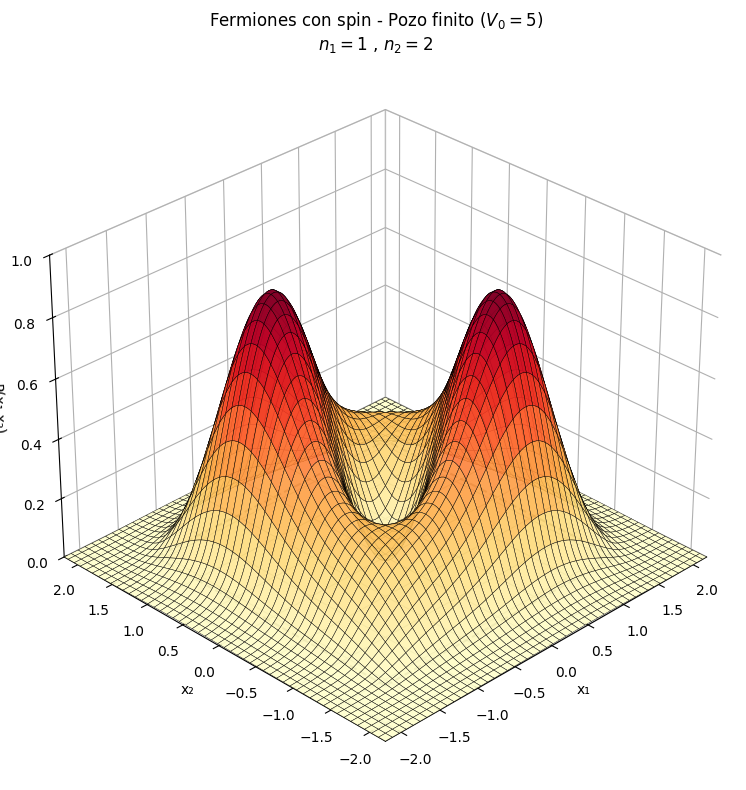

(<Figure size 1000x800 with 1 Axes>,
 <Axes3D: title={'center': 'Fermiones con spin - Pozo finito $(V_0=5)$\n$n_1=1$ , $n_2=2$'}, xlabel='x₁', ylabel='x₂', zlabel='P(x₁,x₂)'>)

In [ ]:
# Ejemplo 1: Graficar dos fermiones con spin en niveles específicos
# Los índices empiezan en 0, así que n1=1 corresponde a índice 0, n2=2 a índice 1, etc.
graficar_fermiones_spin_nivel(0, 1, V0, a)  # Uno en nivel fundamental y otro en primer excitado


Considerando 4 de 4 estados disponibles para T=10


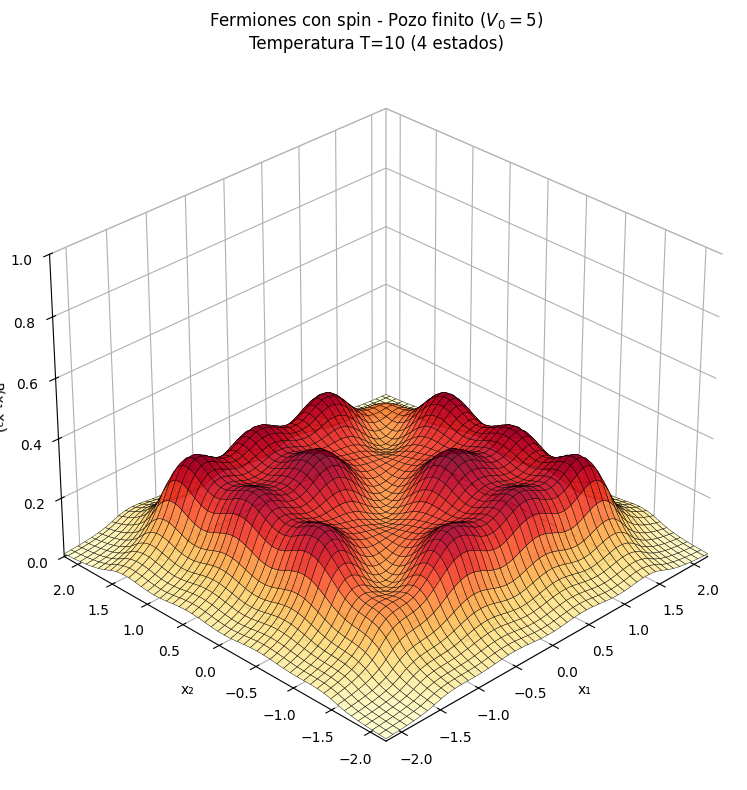

(<Figure size 1000x800 with 1 Axes>,
 <Axes3D: title={'center': 'Fermiones con spin - Pozo finito $(V_0=5)$\nTemperatura T=10 (4 estados)'}, xlabel='x₁', ylabel='x₂', zlabel='P(x₁,x₂)'>)

In [ ]:
graficar_fermiones_spin_termalizado(T=10, V0=V0, a=a)

Considerando 4 de 4 estados disponibles


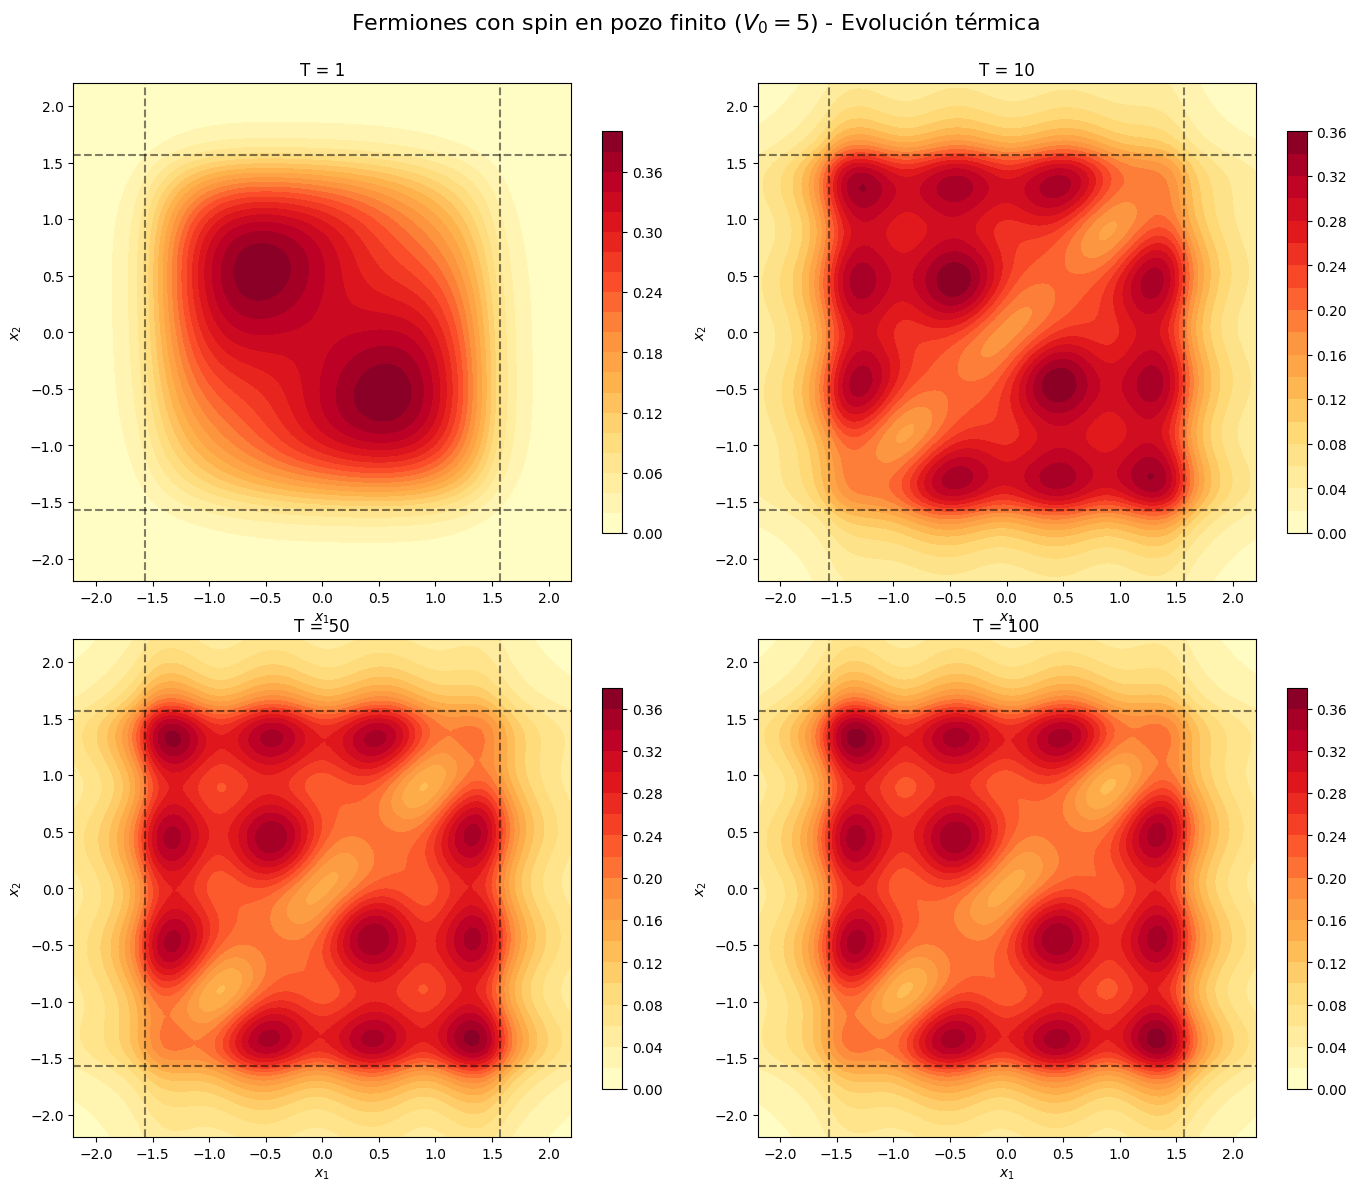

(<Figure size 1400x1200 with 8 Axes>,
 array([<Axes: title={'center': 'T = 1'}, xlabel='$x_1$', ylabel='$x_2$'>,
        <Axes: title={'center': 'T = 10'}, xlabel='$x_1$', ylabel='$x_2$'>,
        <Axes: title={'center': 'T = 50'}, xlabel='$x_1$', ylabel='$x_2$'>,
        <Axes: title={'center': 'T = 100'}, xlabel='$x_1$', ylabel='$x_2$'>],
       dtype=object))

In [ ]:
temperatures = [1, 10, 50, 100]
comparar_temperaturas_fermiones_spin(temperatures, V0=V0, a=a)

## Aumentar la altura del pozo $V_0=5 → V_0=100$

In [ ]:
V0 = 100

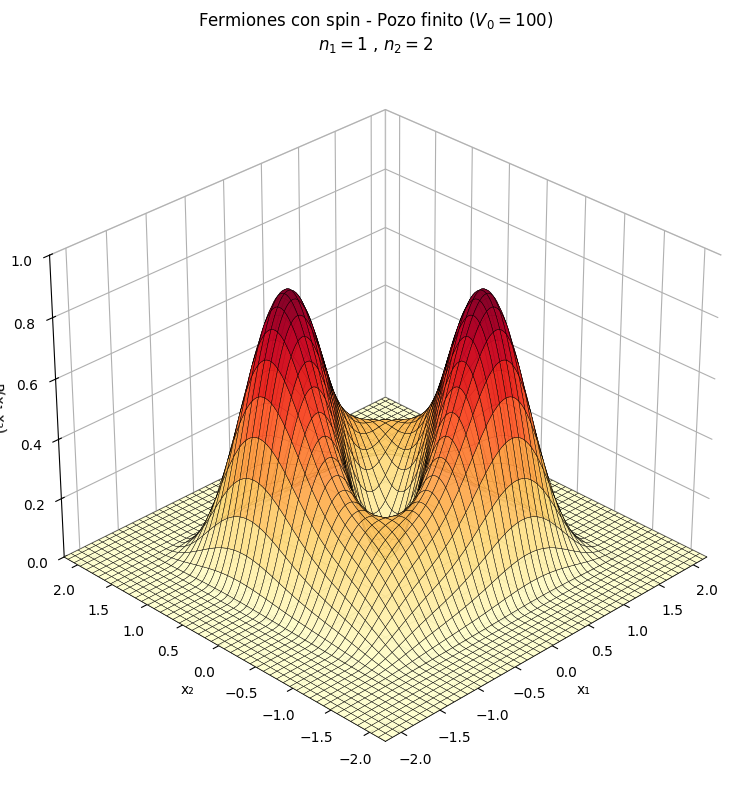

(<Figure size 1000x800 with 1 Axes>,
 <Axes3D: title={'center': 'Fermiones con spin - Pozo finito $(V_0=100)$\n$n_1=1$ , $n_2=2$'}, xlabel='x₁', ylabel='x₂', zlabel='P(x₁,x₂)'>)

In [ ]:
graficar_fermiones_spin_nivel(0, 1, V0, a)

Considerando 15 de 15 estados disponibles para T=10


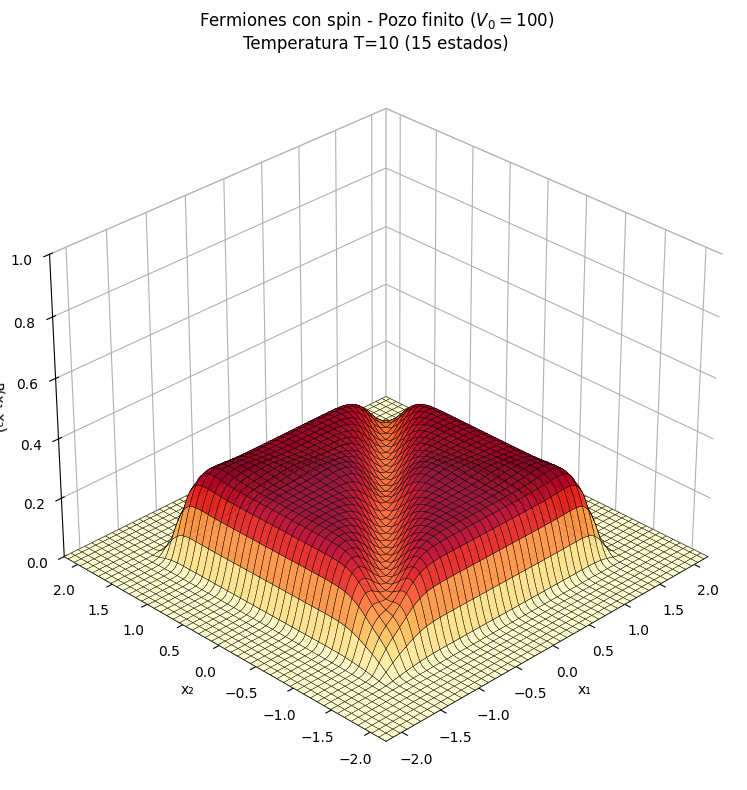

(<Figure size 1000x800 with 1 Axes>,
 <Axes3D: title={'center': 'Fermiones con spin - Pozo finito $(V_0=100)$\nTemperatura T=10 (15 estados)'}, xlabel='x₁', ylabel='x₂', zlabel='P(x₁,x₂)'>)

In [ ]:
graficar_fermiones_spin_termalizado(T=10, V0=V0, a=a)

Considerando 15 de 15 estados disponibles


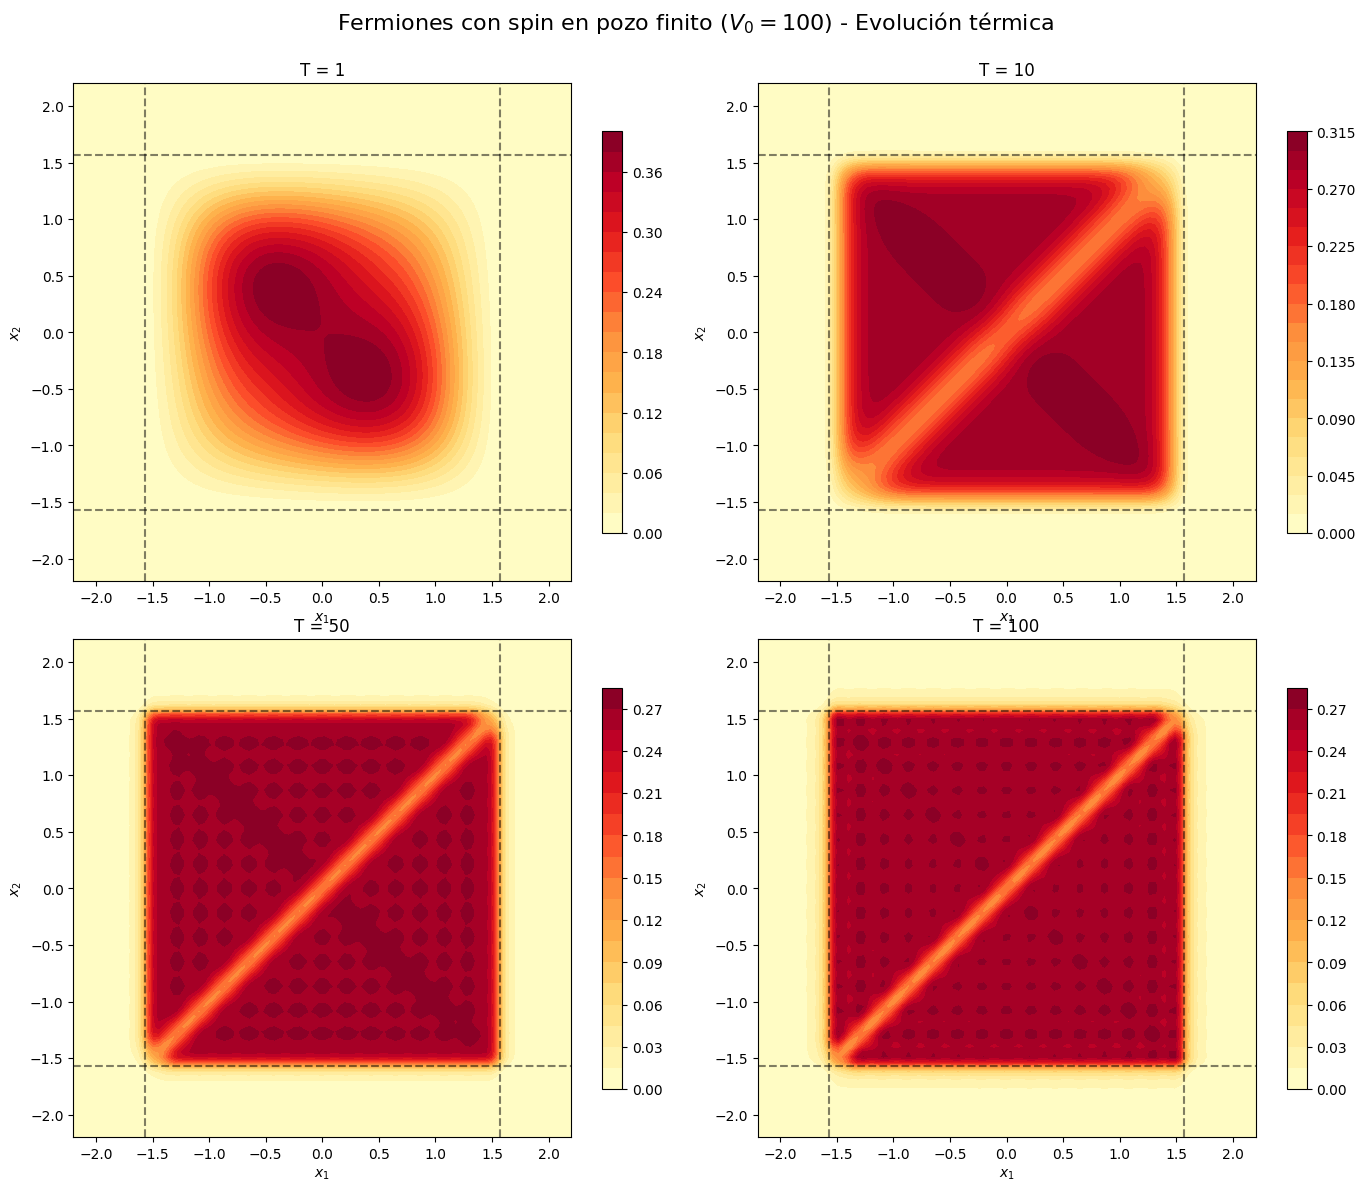

(<Figure size 1400x1200 with 8 Axes>,
 array([<Axes: title={'center': 'T = 1'}, xlabel='$x_1$', ylabel='$x_2$'>,
        <Axes: title={'center': 'T = 10'}, xlabel='$x_1$', ylabel='$x_2$'>,
        <Axes: title={'center': 'T = 50'}, xlabel='$x_1$', ylabel='$x_2$'>,
        <Axes: title={'center': 'T = 100'}, xlabel='$x_1$', ylabel='$x_2$'>],
       dtype=object))

In [ ]:
comparar_temperaturas_fermiones_spin(temperatures, V0=V0, a=a)

In [ ]:
def grafica2D(T, V0=5.0, a=np.pi/2, max_states=None):
    """
    Grafica la densidad de probabilidad para fermiones con spin a una temperatura específica.

    Parámetros:
    - T: Temperatura a graficar
    - V0: Altura del pozo (por defecto 5.0)
    - a: Mitad del ancho del pozo (por defecto π/2)
    - max_states: Número máximo de estados a considerar. Si es None, usa todos los estados disponibles.
    """
    # Obtener los niveles de energía
    energies, parities = get_energy_levels(V0, a)

    # Si max_states es None, usar todos los estados disponibles
    if max_states is None:
        max_states = len(energies)
    else:
        max_states = min(max_states, len(energies))

    # Imprimir información sobre los estados que se están considerando
    #print(f"Considerando {max_states} de {len(energies)} estados disponibles para T={T}")

    # Crear figura
    fig, ax = plt.subplots(figsize=(10, 8))

    # Crear malla de puntos
    x = np.linspace(-2.2, 2.2, 200)
    X1, X2 = np.meshgrid(x, x)

    # Calcular la densidad térmica
    #print(f"Calculando T = {T}...")
    density = fermion_spin_density_thermal(X1, X2, T, energies, parities, V0, a, max_states)

    # Graficar como mapa de contorno
    im = ax.contourf(X1, X2, density, levels=50, cmap='YlOrRd')
    #ax.set_title(f'Fermiones con spin - Pozo finito (V0={V0:.2f})\nTemperatura T = {T}')
    ax.set_xlabel(r'$x_1$')
    ax.set_ylabel(r'$x_2$')
    ax.set_aspect('equal')

    # Marcar límites del pozo
    ax.axvline(-a, color='white', linestyle='--', alpha=0.7)
    ax.axvline(a, color='white', linestyle='--', alpha=0.7)
    ax.axhline(-a, color='white', linestyle='--', alpha=0.7)
    ax.axhline(a, color='white', linestyle='--', alpha=0.7)

    # Añadir barra de color
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label('Densidad de probabilidad')

    plt.tight_layout()
    plt.show()

    return fig, ax

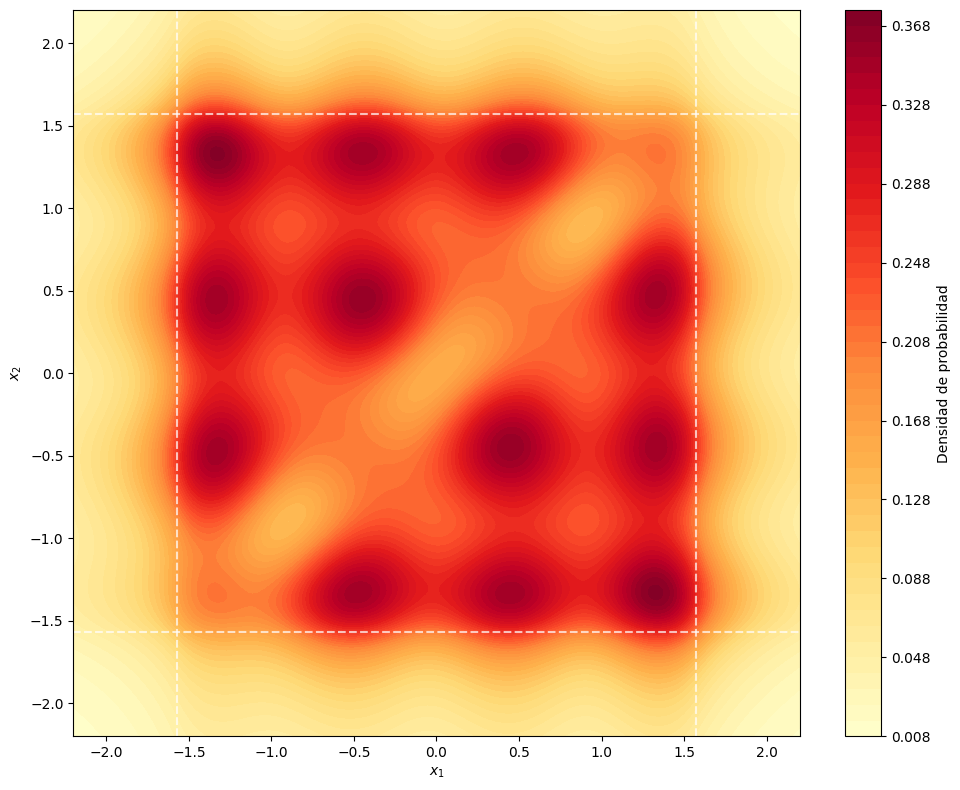

(<Figure size 1000x800 with 2 Axes>, <Axes: xlabel='$x_1$', ylabel='$x_2$'>)

In [ ]:
grafica2D(T=100, V0=5, a=a)

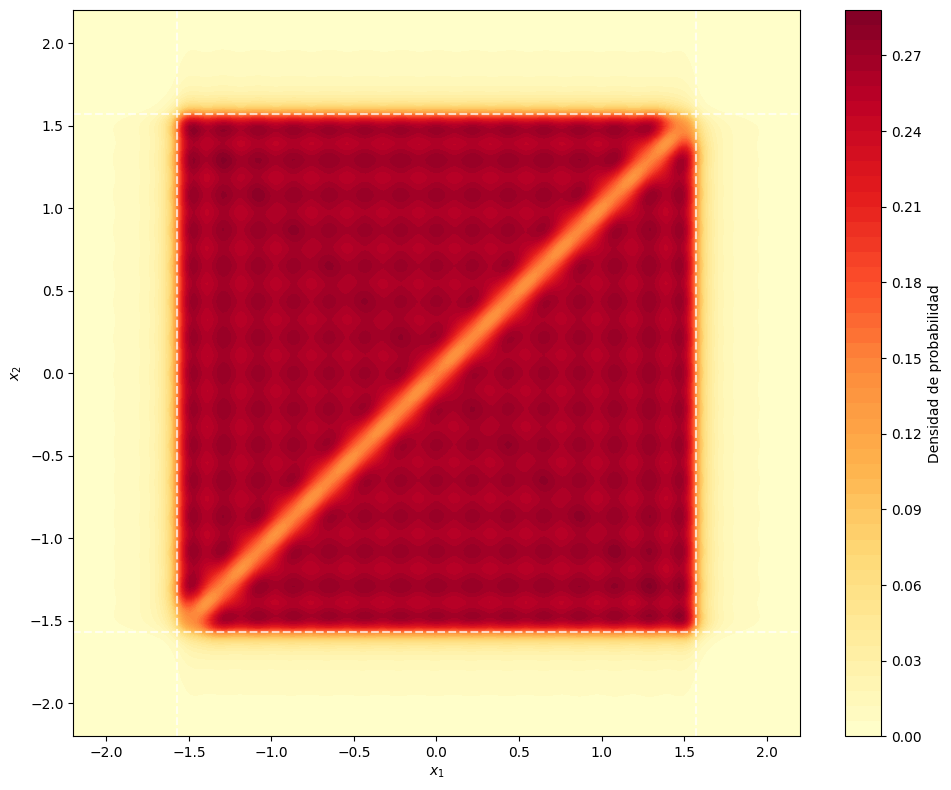

(<Figure size 1000x800 with 2 Axes>, <Axes: xlabel='$x_1$', ylabel='$x_2$'>)

In [ ]:
grafica2D(T=100, V0=100, a=a)